# Radar part - Sentinel-1 Imagery

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import rasterio

DATA = Path("./scenes")
S1_BANDS = ["vv", "vh"]

Text(0.5, 1.0, 'VH Puszcza - 2024-08-13')

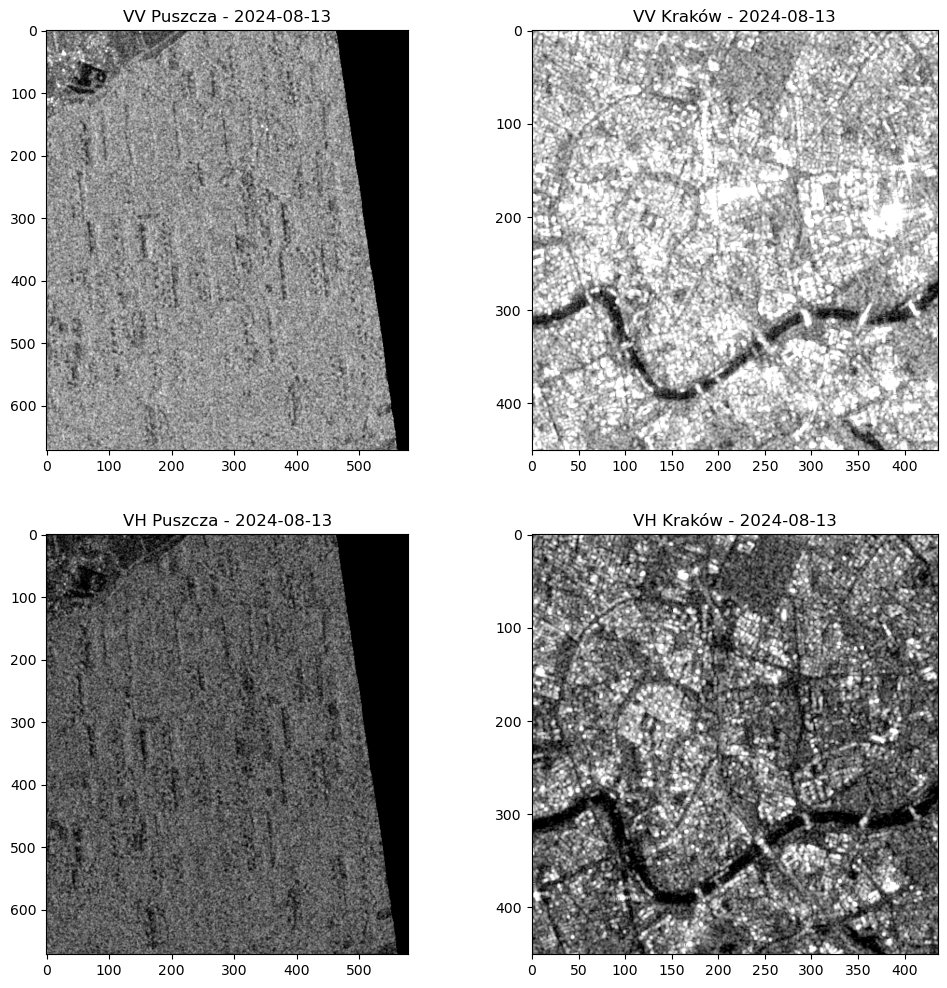

In [ ]:
S1_BANDS = ["vv", "vh"]

def load_s1(prefix: str) -> dict[str, np.ndarray]:
    out = {}
    for b in S1_BANDS:
        with rasterio.open(DATA / f"{prefix}_{b}.tif") as src:
            x = src.read(1).astype(np.float32)
        out[b] = 10 * np.log10(np.maximum(x, 1e-10))
    return out

urban = load_s1("s1_urban")
natural = load_s1("s1_natural")


_, ax = plt.subplots(2, 2, figsize=(12, 12))


ax[0, 1].imshow(urban["vv"], cmap="gray", vmin=-20, vmax=0)
ax[0, 1].set_title("VV Kraków - 2024-08-13")
ax[0, 0].imshow(natural["vv"], cmap="gray", vmin=-20, vmax=0)
ax[0, 0].set_title("VV Puszcza - 2024-08-13")

ax[1, 1].imshow(urban["vh"], cmap="gray", vmin=-20, vmax=0)
ax[1, 1].set_title("VH Kraków - 2024-08-13")
ax[1, 0].imshow(natural["vh"], cmap="gray", vmin=-20, vmax=0)
ax[1, 0].set_title("VH Puszcza - 2024-08-13")

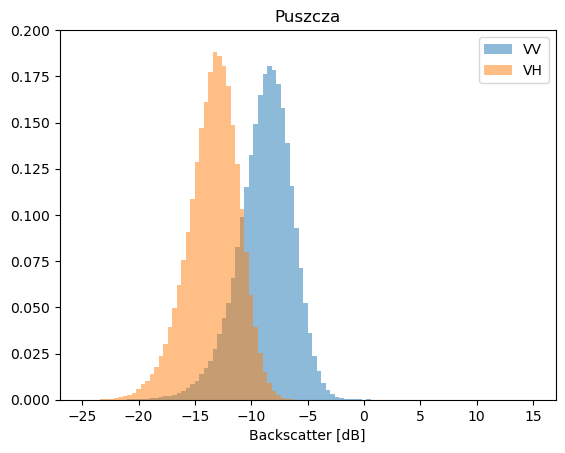

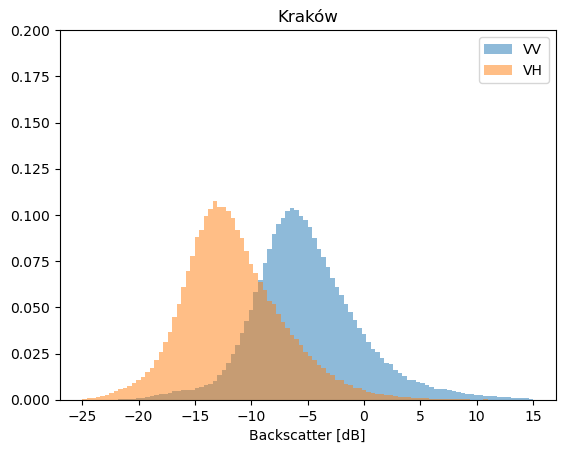

In [14]:
for name, data in [("Puszcza", natural), ("Kraków", urban)]:
    plt.figure()
    for b, c in [("vv", "C0"), ("vh", "C1")]:
        plt.hist(data[b].ravel(), bins=100, range=(-25, 15), alpha=0.5, label=b.upper(), color=c, density=True)
        plt.ylim(0, 0.2)
    plt.xlabel("Backscatter [dB]"); plt.legend(); plt.title(name)

## SENTINEL-1 Observations

In Sentinel-1 imagery we are not longer looking at the optical image but rather radar product. Thus I will be talking about VV and VH values and their relation.

What is clearly visible, Puszcza histogram has two thin peaks, obtaining values up to 0.175. Most pixels fall in tight dB range. Observed scene is relatively homogenous.

Krakow histogram tends to be more wide-spreaded, VV and VH are not obtaining as high values as in previous histogram. City histogram characterizes with longer tail for both components, whole histogram is more wide-spreaded and it is that way because the imagery characterizes more complex scene with varying areas. Mixed urban surfaces, streets, roads. 

| Fact | Puszcza | Kraków |
|-|-|-|
| Peak height | ~0.18/0.19 | ~0.10/0.11 |
| VH peak | ~ -14 dB | ~ -14 dB |
| VV peak | ~ -8 dB | ~ -6 dB |
| Shape of the peaks | narrower, bigger values, more concentrated around the peak | wide spread, with long tail |